# Calisma 1b - Segmentasyon Metriklerinin Guclendirilmesi

Calisma 1'de cok ajanli sistem Dice'i artirmadi (0.631 -> 0.631), cunku ajanlar ellerindeki segmentasyon
modelinden daha iyi maske uretemez. Bu notebook dogrudan **temel segmentasyonu** guclendirir. Uc kaldirac:

1. **Bilesen politikasi (egitimsiz):** Ilk makaledeki kod her kesitte YALNIZCA en buyuk bileseni tutuyor.
   Oysa test kesitlerinin ~%39'unda pnomotoraks birden fazla bilesenden olusur (iki tarafli / parcali).
   Uzman maskesinin kendisi bile "en buyuk bilesen" kuralindan gecirilince Dice ust siniri 0.919'dur
   (tum bilesenler tutulursa 0.977). Burada esik, min. bilesen alani ve bilesen politikasi (en buyuk / ilk 2 / tumu)
   ve yatay cevirme TTA'si **val setinde** secilir.
2. **Guclu model (egitim ~45-60 dk, T4):** 224x224 parca yerine 512x512 tam cozunurluk kirpmalariyla egitilen,
   ImageNet onegitimli ResNet34 kodlayicili U-Net. **Cok gorevli:** pnomotoraks + akciger (veride hazir olan 2. etiket)
   ayni anda ogrenilir; akciger tahmini son islemede anatomik on bilgi olarak kullanilabilir (pnomotoraks akciger
   parankiminin disindadir). Pozitif bolge agirlikli kirpma, Dice + Focal kayip, karisik hassasiyet (AMP).
3. **(Istege bagli) nnU-Net 2D:** literaturde guclu referans; uzun surer (~2 saat), `RUN_NNUNET = True` ile acilir.

Tum secimler **yalnizca val (17 hasta)** uzerinde yapilir; **test (43 hasta)** sadece raporlanir.
Sonunda val'de en iyi ayar `pnx_calisma1b/guclu_segmenter.json` dosyasina yazilir; Calisma 1 notebook'u
`GUCLU_SEGMENTER = True` ile bu modeli kullanarak cok ajanli sistemi yeniden calistirir.

In [1]:
!pip install -q segmentation_models_pytorch albumentations opencv-python-headless pillow scipy matplotlib pandas scikit-learn
!rm -rf /content/sam2
!git clone -q https://github.com/facebookresearch/sam2.git /content/sam2
%cd /content/sam2
!SAM2_BUILD_CUDA=0 pip install -q -e .
!mkdir -p checkpoints
!wget -q -O /content/sam2/checkpoints/sam2.1_hiera_small.pt https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
%cd /content

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.2 MB/s eta 0:00:00
/content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 13.4 MB/s eta 0:00:00
  Building editable for SAM-2 (pyproject.toml) ... done
/content


### Ortak yardimci modul
Asagidaki hucre `pnx_ortak.py` dosyasini Colab diskine yazar (ilk makaledeki fonksiyonlarin aynisi). Degistirmeniz gerekmez.

In [2]:
%%writefile /content/pnx_ortak.py
# -*- coding: utf-8 -*-
"""
pnx_ortak.py - Uc yeni calismanin (Calisma 1/2/3) ortak yardimci modulu.

Pnomotoraks_sonuc3.ipynb notebook'undaki veri hazirlama, hasta bazli bolme,
U-Net cikarimi (sliding window), SAM2 sinir iyilestirme, birlestirme kurali,
guvenilirlik katsayisi ve metrik fonksiyonlarinin AYNISI buraya tasinmistir.
Boylece uc calisma da:
  * ayni egitilmis U-Net agirligini (pnomotoraks_unet.pth) yeniden egitmeden kullanir,
  * ayni tohumla (SEED=42) ayni train/val/test hasta bolmesini uretir
    (test hastalari ilk makaledekiyle birebir aynidir, sizinti olmaz),
  * ilk makaledeki pipeline'i "temel model" (baseline) olarak birebir yeniden uretir.

Colab'da kullanim:
    import sys; sys.path.insert(0, '/content/drive/MyDrive/pnx_kod')
    import pnx_ortak as po
    po.init_unet(); po.init_sam2_image()
"""
import os, glob, random, time
import numpy as np
import cv2
import torch
from PIL import Image
from scipy import ndimage

# ---------------------------------------------------------------------------
# Yapilandirma (ilk makaleyle ayni degerler)
# ---------------------------------------------------------------------------
RAW_DIR = '/content/drive/MyDrive/CT_goruntuler_anon'
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/pnomotoraks_v3_artifacts'
UNET_WEIGHT_PATH = f'{DRIVE_BACKUP_DIR}/pnomotoraks_unet.pth'

SAM2_REPO_DIR = '/content/sam2'
SAM2_CHECKPOINT = '/content/sam2/checkpoints/sam2.1_hiera_small.pt'
SAM2_CONFIG = 'configs/sam2.1/sam2.1_hiera_s.yaml'

IMAGE_SIZE = 224
PATCH_STRIDE = 224
SEED = 42
PNEUMOTHORAX_LABEL = 1
LUNG_LABEL = 2
TRAIN_RATIO = 0.65
VAL_RATIO = 0.10

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

unet_model = None
sam2_image_predictor = None
_sam2_base_model = None

# Segmentasyon modeli ve son isleme ayarlari. Varsayilanlar ilk makaleyle (Biomedicines) birebir aynidir:
# 224x224 parca U-Net, esik 0.5, 80 pikselden kucuk bilesenleri at, YALNIZCA en buyuk bileseni tut.
# Calisma1b (metrik guclendirme) val setinde daha iyi ayarlari secip guclu_segmenter.json'a yazar;
# load_segmenter_config() ile tum calismalar ayni ayari kullanabilir.
SEG = {
    'kind': 'unet_patch',     # 'unet_patch' (ilk makale) | 'guclu' (tam cozunurluk, cok gorevli model)
    'threshold': 0.5,
    'min_area': 80,
    'keep': 'largest',        # 'largest' | 'all' | 'top2'
    'tta': False,             # yatay cevirme ile test-zamani artirma
    'lung_filter': False,     # yalnizca 'guclu': akciger olasiligi yuksek bolgeye dusen pnomotoraks bilesenlerini at
}
strong_model = None
LAST_LUNG_PROB = None


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------------------
# Veri: hasta indeksi ve hasta bazli bolme (sonuc3 Hucre 4-5 ile birebir ayni)
# ---------------------------------------------------------------------------
def _slice_sort_key(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    return (0, int(stem)) if stem.isdigit() else (1, stem)


def find_pairs_for_patient(patient_dir, numeric_order=False):
    # numeric_order=False: ilk makaledeki gibi alfabetik siralama (bolme ayni kalsin diye).
    # numeric_order=True : kesitleri sayisal sirada dondurur (video/sekans calismalari icin;
    #                      '10.jpg' '2.jpg'den once gelmesin).
    pairs = []
    jpg_files = sorted(glob.glob(os.path.join(patient_dir, '*.jpg')))
    if numeric_order:
        jpg_files = sorted(jpg_files, key=_slice_sort_key)
    for jpg_path in jpg_files:
        stem = os.path.splitext(os.path.basename(jpg_path))[0]
        png_path = os.path.join(patient_dir, stem + '.png')
        if os.path.exists(png_path):
            pairs.append((jpg_path, png_path))
    return pairs


def build_patient_split(raw_dir=RAW_DIR, seed=SEED, numeric_order=True):
    """Ilk makaledeki hasta bazli bolmeyi birebir yeniden uretir.

    Donus: patient_index {pid: [(jpg, png), ...]}, split_of_patient {pid: 'train'|'val'|'test'}
    """
    patient_dirs = sorted([d for d in glob.glob(os.path.join(raw_dir, '*')) if os.path.isdir(d)])
    patient_index = {}
    for pdir in patient_dirs:
        pid = os.path.basename(pdir)
        pairs = find_pairs_for_patient(pdir, numeric_order=numeric_order)
        if len(pairs) > 0:
            patient_index[pid] = pairs

    # Uyari: yalnizca kucuk harfli .jpg/.png ciftleri kullanilir (ilk makaleyle ayni). .jpeg veya .PNG gibi
    # uzantilar Linux/Colab'da eslesmez ve atlanir; bolmenin ilk makaleyle ayni kalmasi icin bilincli olarak
    # degistirilmemistir. Atlanan dosyalar burada listelenir.
    atlanan = [os.path.relpath(f, raw_dir) for d in patient_dirs for f in glob.glob(os.path.join(d, '*'))
               if not f.endswith(('.jpg', '.png'))]
    if atlanan:
        print(f'UYARI: standart disi uzantili {len(atlanan)} dosya kullanilmadi (ornek: {atlanan[:3]})')

    patient_ids = sorted(patient_index.keys())
    rng = random.Random(seed)
    rng.shuffle(patient_ids)
    n = len(patient_ids)
    n_train = int(round(n * TRAIN_RATIO))
    n_val = int(round(n * VAL_RATIO))
    split_of_patient = {}
    for pid in patient_ids[:n_train]:
        split_of_patient[pid] = 'train'
    for pid in patient_ids[n_train:n_train + n_val]:
        split_of_patient[pid] = 'val'
    for pid in patient_ids[n_train + n_val:]:
        split_of_patient[pid] = 'test'
    return patient_index, split_of_patient


def load_image_rgb(image_path):
    image = cv2.imread(image_path, cv2.IMREAD_COLOR)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def load_label_map(mask_path):
    m = np.array(Image.open(mask_path))
    if m.ndim == 3:
        m = m[..., 0]
    return m


def load_binary_mask(mask_path, label=PNEUMOTHORAX_LABEL):
    return (load_label_map(mask_path) == label).astype(np.uint8)


# ---------------------------------------------------------------------------
# Morfolojik yardimcilar ve rapor yardimcilari (sonuc3 Hucre 19)
# ---------------------------------------------------------------------------
def clean_mask(mask, min_area=80):
    mask = (mask > 0).astype(np.uint8)
    labeled, num = ndimage.label(mask)
    out = np.zeros_like(mask, dtype=np.uint8)
    for i in range(1, num + 1):
        region = (labeled == i)
        if region.sum() >= min_area:
            out[region] = 1
    return out


def largest_component(mask):
    labeled, num = ndimage.label(mask)
    if num == 0:
        return mask.astype(np.uint8)
    sizes = ndimage.sum(mask, labeled, range(1, num + 1))
    return (labeled == (int(np.argmax(sizes)) + 1)).astype(np.uint8)


def keep_components(mask, keep=None):
    keep = SEG['keep'] if keep is None else keep
    mask = (mask > 0).astype(np.uint8)
    if keep == 'largest':
        return largest_component(mask)
    if keep == 'top2':
        labeled, num = ndimage.label(mask)
        if num <= 2:
            return mask
        sizes = ndimage.sum(mask, labeled, range(1, num + 1))
        top = np.argsort(sizes)[::-1][:2] + 1
        return np.isin(labeled, top).astype(np.uint8)
    return mask


def postprocess_mask(mask, min_area=None, keep=None):
    """Ikili maskeye SEG ayarlarina gore kucuk bilesen temizligi + bilesen politikasi uygular."""
    return keep_components(clean_mask(mask, SEG['min_area'] if min_area is None else min_area), keep)


def area_ratio(mask):
    return float(mask.sum() / mask.size)


def estimate_side(mask, radiological_convention=True):
    """Pnomotoraksin tarafini tahmin eder.

    DIKKAT: Aksiyel BT goruntuleri radyolojik konvansiyonda gosterilir; goruntunun
    SOL yarisi hastanin SAG tarafidir. Ilk makaledeki kodda (sonuc3) goruntunun sol
    yarisi 'sol' olarak etiketleniyordu (radyolojik konvansiyon dikkate alinmamisti).
    Yeni calismalarda varsayilan olarak radyolojik konvansiyon kullanilir; ilk
    makaleyle birebir karsilastirma gerekirse radiological_convention=False verin.
    """
    if mask.sum() == 0:
        return 'belirgin degil'
    h, w = mask.shape
    img_left = mask[:, :w // 2].sum()
    img_right = mask[:, w // 2:].sum()
    if radiological_convention:
        side_of_img_left, side_of_img_right = 'sag', 'sol'
    else:
        side_of_img_left, side_of_img_right = 'sol', 'sag'
    if img_left > img_right * 1.2:
        return side_of_img_left
    elif img_right > img_left * 1.2:
        return side_of_img_right
    return 'bilateral'


def estimate_extent(mask):
    r = area_ratio(mask)
    if r < 0.005:
        return 'cok kucuk'
    elif r < 0.02:
        return 'kucuk'
    elif r < 0.06:
        return 'orta'
    return 'genis'


def make_overlay(image_np, mask, color=(255, 0, 0), alpha=0.35):
    overlay = image_np.copy()
    m = mask.astype(bool)
    col = np.array(color, dtype=np.float32)
    overlay[m] = ((1 - alpha) * overlay[m] + alpha * col).astype(np.uint8)
    return overlay


def mask_iou(mask_a, mask_b):
    inter = np.logical_and(mask_a > 0, mask_b > 0).sum()
    union = np.logical_or(mask_a > 0, mask_b > 0).sum()
    return 0.0 if union == 0 else float(inter) / float(union)


def mask_box(mask, margin=10):
    h, w = mask.shape
    ys, xs = np.where(mask > 0)
    return np.array([max(0, xs.min() - margin), max(0, ys.min() - margin),
                     min(w - 1, xs.max() + margin), min(h - 1, ys.max() + margin)])


# ---------------------------------------------------------------------------
# Metrikler (sonuc3 Hucre 12)
# ---------------------------------------------------------------------------
def segmentation_metrics(pred_mask, gt_mask, eps=1e-6):
    p = pred_mask.flatten().astype(np.uint8)
    g = gt_mask.flatten().astype(np.uint8)
    tp = int(np.sum((p == 1) & (g == 1)))
    tn = int(np.sum((p == 0) & (g == 0)))
    fp = int(np.sum((p == 1) & (g == 0)))
    fn = int(np.sum((p == 0) & (g == 1)))
    sens = (tp + eps) / (tp + fn + eps)
    prec = (tp + eps) / (tp + fp + eps)
    return {
        'dice': (2 * tp + eps) / (2 * tp + fp + fn + eps),
        'iou': (tp + eps) / (tp + fp + fn + eps),
        'accuracy': (tp + tn + eps) / (tp + tn + fp + fn + eps),
        'sensitivity': sens,
        'specificity': (tn + eps) / (tn + fp + eps),
        'precision': prec,
        'f1': (2 * prec * sens + eps) / (prec + sens + eps),
    }


def hd95_pixels(pred_mask, gt_mask):
    pred_mask = (pred_mask > 0).astype(np.uint8)
    gt_mask = (gt_mask > 0).astype(np.uint8)
    if pred_mask.sum() == 0 or gt_mask.sum() == 0:
        return float('nan')
    pb = pred_mask - ndimage.binary_erosion(pred_mask).astype(np.uint8)
    gb = gt_mask - ndimage.binary_erosion(gt_mask).astype(np.uint8)
    if pb.sum() == 0 or gb.sum() == 0:
        return float('nan')
    gt_dt = ndimage.distance_transform_edt(1 - gb)
    pr_dt = ndimage.distance_transform_edt(1 - pb)
    return float(max(np.percentile(gt_dt[pb > 0], 95), np.percentile(pr_dt[gb > 0], 95)))


def hemithorax_counts(pred_mask, gt_mask, min_pixels=50):
    """Yari-toraks (goruntunun sol/sag yarisi) duzeyinde tespit sayimlari.

    Veri setindeki kesitlerin neredeyse tamami pnomotoraks pozitiftir (852/853), bu yuzden kesit
    duzeyinde ozgulluk olculemez. Pnomotoraks cogunlukla tek tarafli oldugundan, GT'de pnomotoraks
    olmayan karsi yari-toraks dogal bir negatif ornektir; burada tahmin edilen maske varsa yanlis pozitiftir.
    Donus: {'tp','fn','tn','fp'} (iki yari uzerinden toplam)."""
    w = gt_mask.shape[1]
    c = {'tp': 0, 'fn': 0, 'tn': 0, 'fp': 0}
    for sl in (slice(0, w // 2), slice(w // 2, w)):
        g = gt_mask[:, sl].sum() >= min_pixels
        p = pred_mask[:, sl].sum() >= min_pixels
        c['tp' if g and p else 'fn' if g else 'fp' if p else 'tn'] += 1
    return c


def dice_3d(pred_vol, gt_vol, eps=1e-6):
    p = pred_vol > 0
    g = gt_vol > 0
    inter = np.logical_and(p, g).sum()
    return float((2 * inter + eps) / (p.sum() + g.sum() + eps))


def bootstrap_ci(values, n_boot=2000, alpha=0.05, seed=SEED):
    values = np.asarray([v for v in values if not np.isnan(v)])
    if len(values) == 0:
        return float('nan'), float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, len(values), replace=True).mean() for _ in range(n_boot)]
    return float(values.mean()), float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))


# ---------------------------------------------------------------------------
# U-Net (sonuc3 Hucre 11 + 19)
# ---------------------------------------------------------------------------
def init_unet(weight_path=UNET_WEIGHT_PATH):
    global unet_model
    import segmentation_models_pytorch as smp
    unet_model = smp.Unet(encoder_name='mobilenet_v2', encoder_weights=None,
                          in_channels=3, classes=1, activation=None).to(DEVICE)
    unet_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    unet_model.eval()
    print('U-Net yuklendi:', weight_path)
    return unet_model


_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def _to_tensor(patch_rgb):
    x = (patch_rgb.astype(np.float32) / 255.0 - _MEAN) / _STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)


def unet_prob_map(image_np, tta=None):
    """Aktif segmentasyon modeliyle tam goruntu pnomotoraks olasilik haritasi (HxW, 0-1).
    SEG['kind'] == 'guclu' ise tam cozunurluk modeli, aksi halde ilk makaledeki parca U-Net kullanilir."""
    global LAST_LUNG_PROB
    tta = SEG['tta'] if tta is None else tta
    fn = _strong_prob if SEG['kind'] == 'guclu' else _patch_unet_prob_map
    p, lung = fn(image_np)
    if tta:
        p2, lung2 = fn(np.ascontiguousarray(image_np[:, ::-1]))
        p = (p + p2[:, ::-1]) / 2
        if lung is not None:
            lung = (lung + lung2[:, ::-1]) / 2
    LAST_LUNG_PROB = lung
    return p


@torch.no_grad()
def _strong_prob(image_np):
    h, w = image_np.shape[:2]
    H, W = int(np.ceil(h / 32) * 32), int(np.ceil(w / 32) * 32)
    img = cv2.copyMakeBorder(image_np, 0, H - h, 0, W - w, cv2.BORDER_CONSTANT, value=0)
    x = _to_tensor(img).to(DEVICE)
    with torch.autocast('cuda', enabled=(DEVICE == 'cuda')):
        out = torch.sigmoid(strong_model(x).float())[0].cpu().numpy()
    lung = out[1, :h, :w] if out.shape[0] > 1 else None
    return out[0, :h, :w], lung


def init_strong_model(weight_path, arch='Unet', encoder='resnet34', classes=2):
    global strong_model
    import segmentation_models_pytorch as smp
    strong_model = getattr(smp, arch)(encoder_name=encoder, encoder_weights=None, in_channels=3, classes=classes).to(DEVICE)
    strong_model.load_state_dict(torch.load(weight_path, map_location=DEVICE))
    strong_model.eval()
    SEG['kind'] = 'guclu'
    print('Guclu segmentasyon modeli yuklendi:', weight_path, arch, encoder)
    return strong_model


def load_segmenter_config(path):
    """Calisma1b'nin urettigi guclu_segmenter.json'u yukler (model + val'de secilen son isleme)."""
    import json as _json
    cfg = _json.load(open(path))
    if cfg.get('kind') == 'guclu':
        init_strong_model(cfg['weight_path'], cfg.get('arch', 'Unet'), cfg.get('encoder', 'resnet34'))
    elif unet_model is None:
        init_unet()
    for k in ('kind', 'threshold', 'min_area', 'keep', 'tta', 'lung_filter'):
        if k in cfg:
            SEG[k] = cfg[k]
    print('Segmenter ayari:', SEG)
    return cfg


@torch.no_grad()
def _patch_unet_prob_map(image_np, patch_size=IMAGE_SIZE, stride=PATCH_STRIDE, batch_size=16):
    """Kaydirmali pencere ile tam goruntu olasilik haritasi (HxW, 0-1) - ilk makaledeki U-Net."""
    h, w = image_np.shape[:2]
    ys = [0] if h <= patch_size else sorted(set(list(range(0, h - patch_size, stride)) + [h - patch_size]))
    xs = [0] if w <= patch_size else sorted(set(list(range(0, w - patch_size, stride)) + [w - patch_size]))
    prob_map = np.zeros((h, w), dtype=np.float32)
    count_map = np.zeros((h, w), dtype=np.float32)
    coords, tensors = [], []
    for y in ys:
        for x in xs:
            patch = image_np[y:y + patch_size, x:x + patch_size]
            ph, pw = patch.shape[:2]
            if ph < patch_size or pw < patch_size:
                patch = cv2.copyMakeBorder(patch, 0, patch_size - ph, 0, patch_size - pw, cv2.BORDER_CONSTANT, value=0)
            coords.append((y, x, ph, pw))
            tensors.append(_to_tensor(patch))
    for i in range(0, len(tensors), batch_size):
        batch = torch.cat(tensors[i:i + batch_size]).to(DEVICE)
        probs = torch.sigmoid(unet_model(batch))[:, 0].cpu().numpy()
        for (y, x, ph, pw), pr in zip(coords[i:i + batch_size], probs):
            prob_map[y:y + ph, x:x + pw] += pr[:ph, :pw]
            count_map[y:y + ph, x:x + pw] += 1.0
    count_map[count_map == 0] = 1.0
    return prob_map / count_map, None


def mask_from_prob(prob, lung_prob=None, threshold=None, min_area=None, keep=None, lung_filter=None):
    threshold = SEG['threshold'] if threshold is None else threshold
    lung_filter = SEG['lung_filter'] if lung_filter is None else lung_filter
    m = clean_mask((prob > threshold).astype(np.uint8), SEG['min_area'] if min_area is None else min_area)
    if lung_filter and lung_prob is not None and m.sum() > 0:
        # Pnomotoraks akciger parankiminin DISINDA (plevral bosluk) yer alir; akciger olasiligi
        # yuksek bolgeyle cogunlukla ortusen bilesenler yanlis pozitif kabul edilir.
        lab, n = ndimage.label(m)
        for j in range(1, n + 1):
            reg = lab == j
            if lung_prob[reg].mean() > 0.5:
                m[reg] = 0
    return keep_components(m, keep)


def unet_predict(image_np, threshold=None):
    """sonuc3'teki unet_predict_external ile ayni cikti: (maske, guven, olasilik haritasi).
    Varsayilan SEG ayarlariyla ilk makaleyle birebir ayni sonucu verir."""
    prob = unet_prob_map(image_np)
    mask = mask_from_prob(prob, LAST_LUNG_PROB, threshold=threshold)
    return mask, float(prob.max()), prob


# ---------------------------------------------------------------------------
# SAM2 (goruntu modu; sonuc3 Hucre 18-19)
# ---------------------------------------------------------------------------
def _sam2_import():
    import sys
    if SAM2_REPO_DIR not in sys.path:
        sys.path.insert(0, SAM2_REPO_DIR)


def init_sam2_image():
    global sam2_image_predictor, _sam2_base_model
    _sam2_import()
    from sam2.build_sam import build_sam2
    from sam2.sam2_image_predictor import SAM2ImagePredictor
    _sam2_base_model = build_sam2(config_file=SAM2_CONFIG, ckpt_path=SAM2_CHECKPOINT, device=DEVICE)
    sam2_image_predictor = SAM2ImagePredictor(_sam2_base_model)
    print('SAM2 (goruntu modu) hazir.')
    return sam2_image_predictor


def init_sam2_video(offload_video_to_cpu=False):
    _sam2_import()
    from sam2.build_sam import build_sam2_video_predictor
    vp = build_sam2_video_predictor(SAM2_CONFIG, SAM2_CHECKPOINT, device=DEVICE)
    print('SAM2 (video modu) hazir.')
    return vp


@torch.no_grad()
def sam2_set_image(image_np):
    sam2_image_predictor.set_image(image_np)


@torch.no_grad()
def sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10, multimask_select='score',
                 image_already_set=False):
    """SAM2 goruntu modu tahmini.

    prompt_type: 'box' | 'point' | 'box+point'
    multimask_select: 'score' (ilk makaledeki gibi en yuksek SAM skoru) |
                      'agreement' (U-Net maskesiyle en yuksek IoU'lu aday)
    SEG['keep'] != 'largest' ise U-Net maskesinin her bagli bileseni (or. iki tarafli pnomotoraks)
    icin ayri istem verilir ve sonuclar birlestirilir.
    """
    if not image_already_set:
        sam2_image_predictor.set_image(image_np)
    if SEG['keep'] != 'largest' and unet_mask.sum() > 0:
        lab, n = ndimage.label(unet_mask > 0)
        if n > 1:
            out, skorlar, alanlar = np.zeros_like(unet_mask, dtype=np.uint8), [], []
            for j in range(1, n + 1):
                comp = (lab == j).astype(np.uint8)
                m, s = _sam2_tek(image_np, comp, prompt_type, box_margin, multimask_select)
                out = np.logical_or(out, m).astype(np.uint8)
                skorlar.append(s); alanlar.append(comp.sum())
            return keep_components(out), float(np.average(skorlar, weights=alanlar))
    return _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select)


def _sam2_tek(image_np, unet_mask, prompt_type, box_margin, multimask_select):
    h, w = image_np.shape[:2]
    has_mask = unet_mask.sum() > 0
    box = mask_box(unet_mask, box_margin) if has_mask else np.array([int(w * .05), int(h * .05), int(w * .95), int(h * .95)])
    if has_mask:
        ys, xs = np.where(unet_mask > 0)
        # Agirlik merkezi maskenin disina dusebilir (hilal seklindeki pnomotoraks);
        # bu yuzden maske icinde merkeze en yakin piksel kullanilir.
        cy, cx = ys.mean(), xs.mean()
        j = int(np.argmin((ys - cy) ** 2 + (xs - cx) ** 2))
        point = np.array([[int(xs[j]), int(ys[j])]])
    else:
        point = np.array([[w // 2, h // 2]])

    kwargs = dict(multimask_output=True)
    if prompt_type == 'box':
        kwargs.update(point_coords=None, point_labels=None, box=box)
    elif prompt_type == 'point':
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=None)
    else:
        kwargs.update(point_coords=point, point_labels=np.array([1]), box=box)
    masks, scores, _ = sam2_image_predictor.predict(**kwargs)

    # Tek bir bilesen/istem icin SAM2 cikti adayinin en buyuk bileseni alinir (ilk makaleyle ayni).
    cands = [largest_component(clean_mask(m.astype(np.uint8))) for m in masks]
    if multimask_select == 'agreement' and has_mask:
        best = int(np.argmax([mask_iou(c, unet_mask) for c in cands]))
    else:
        best = int(np.argmax(scores))
    return cands[best], float(scores[best])


def combine_masks(unet_mask, sam_mask, min_agreement_iou=0.3):
    # sonuc3 Hucre 19 ile ayni kural: U-Net negatifse bos; uyum dusukse U-Net'e geri dus.
    # Bilesen politikasi SEG['keep'] ile belirlenir (varsayilan 'largest' = ilk makale).
    if unet_mask.sum() == 0:
        return np.zeros_like(sam_mask, dtype=np.uint8)
    if mask_iou(unet_mask, sam_mask) < min_agreement_iou:
        return postprocess_mask(unet_mask)
    return postprocess_mask(np.logical_or(unet_mask > 0, sam_mask > 0).astype(np.uint8))


def compute_reliability(unet_conf, sam_conf, final_mask, wU=0.35, wS=0.45, wA=0.20):
    area_term = min(area_ratio(final_mask) / 0.03, 1.0)
    return float(max(0.0, min(1.0, wU * unet_conf + wS * sam_conf + wA * area_term)))


def baseline_pipeline(image_np):
    """Ilk makaledeki (Biomedicines) tek gecisli pipeline: U-Net -> SAM2 kutu -> birlestirme."""
    t0 = time.time()
    unet_mask, unet_conf, prob = unet_predict(image_np)
    sam_mask, sam_conf = sam2_predict(image_np, unet_mask, prompt_type='box', box_margin=10)
    final = combine_masks(unet_mask, sam_mask)
    return {
        'mask': final, 'unet_mask': unet_mask, 'sam_mask': sam_mask,
        'unet_conf': unet_conf, 'sam_conf': sam_conf, 'prob': prob,
        'reliability': compute_reliability(unet_conf, sam_conf, final),
        'time_s': time.time() - t0,
    }


# ---------------------------------------------------------------------------
# Anatomik olabilirlik yardimcilari (Calisma 1 dogrulama ajani icin)
# ---------------------------------------------------------------------------
def body_mask(image_np, thr=20):
    """Govde (vucut) maskesi: goruntu esiklenir, en buyuk bilesen alinir, delikleri doldurulur.
    Pnomotoraks havasi govde ICINDE, hasta disindaki hava govde DISINDA kalir."""
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    m = (gray > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    m = largest_component(m)
    return ndimage.binary_fill_holes(m).astype(np.uint8)


def mean_intensity_in_mask(image_np, mask):
    gray = cv2.cvtColor(image_np, cv2.COLOR_RGB2GRAY) if image_np.ndim == 3 else image_np
    return float(gray[mask > 0].mean()) if mask.sum() > 0 else float('nan')


# ---------------------------------------------------------------------------
# VLM (Qwen2-VL; sonuc3 Hucre 30-31)
# ---------------------------------------------------------------------------
vlm_model = None
vlm_processor = None
VLM_MODEL_ID = 'Qwen/Qwen2-VL-2B-Instruct'


def init_vlm(model_id=VLM_MODEL_ID):
    global vlm_model, vlm_processor, VLM_MODEL_ID
    from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
    VLM_MODEL_ID = model_id
    vlm_model = Qwen2VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.float16, device_map='auto')
    vlm_processor = AutoProcessor.from_pretrained(model_id)
    print('VLM hazir:', model_id)


@torch.no_grad()
def vlm_generate(image_pil, prompt_text, max_new_tokens=400, temperature=0.6, seed=None):
    from qwen_vl_utils import process_vision_info
    if seed is not None:
        torch.manual_seed(seed)
    messages = [{'role': 'user', 'content': [{'type': 'image', 'image': image_pil}, {'type': 'text', 'text': prompt_text}]}]
    chat = vlm_processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = vlm_processor(text=[chat], images=image_inputs, videos=video_inputs, padding=True, return_tensors='pt').to(DEVICE)
    out = vlm_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=temperature, top_p=0.9, repetition_penalty=1.3)
    trimmed = [o[len(i):] for i, o in zip(inputs.input_ids, out)]
    return vlm_processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)[0].strip()

Writing /content/pnx_ortak.py


In [3]:
import os, sys, json, time, random, itertools, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from scipy import ndimage, stats

from google.colab import drive
drive.mount('/content/drive')
sys.path.insert(0, '/content')
import pnx_ortak as po

po.set_seed()
OUT_DIR = '/content/drive/MyDrive/pnx_calisma1b'
os.makedirs(OUT_DIR, exist_ok=True)
print('Cihaz:', po.DEVICE)

Mounted at /content/drive
Cihaz: cuda


## 1. Veri (ilk makaleyle ayni hasta bolmesi) - tam kesitler bellege alinir

In [4]:
patient_index, split_of_patient = po.build_patient_split()
SPLIT = {s: sorted(p for p, ss in split_of_patient.items() if ss == s) for s in ('train', 'val', 'test')}


def yukle(hastalar):
    imgs, labs, ids = [], [], []
    for pid in hastalar:
        for jpg, png in patient_index[pid]:
            imgs.append(po.load_image_rgb(jpg))
            labs.append(po.load_label_map(png).astype(np.uint8))   # 0 arka plan, 1 pnomotoraks, 2 akciger
            ids.append((pid, os.path.basename(jpg)))
    return imgs, labs, ids


VERI = {s: yukle(SPLIT[s]) for s in SPLIT}
for s in SPLIT:
    print(f'{s}: {len(SPLIT[s])} hasta, {len(VERI[s][0])} kesit')
GT = {s: [(l == po.PNEUMOTHORAX_LABEL).astype(np.uint8) for l in VERI[s][1]] for s in ('val', 'test')}
cok_bilesen = [ndimage.label(po.clean_mask(g))[1] > 1 for g in GT['test']]
print(f'Test kesitlerinde birden fazla bilesenli pnomotoraks orani: {np.mean(cok_bilesen):.3f}')

UYARI: standart disi uzantili 27 dosya kullanilmadi (ornek: ['1426520/4.PNG', '1637290/5.jpeg', '1757286/2.jpeg'])
train: 111 hasta, 556 kesit
val: 17 hasta, 85 kesit
test: 43 hasta, 211 kesit
Test kesitlerinde birden fazla bilesenli pnomotoraks orani: 0.374


## 2. Degerlendirme yardimcilari (Calisma 1 ile ayni metrikler)

In [5]:
MASKELER = {}   # test maskeleri (sekiller icin)


def kesit_tablosu(ad, maskeler, split='test'):
    if split == 'test':
        MASKELER[ad] = maskeler
    rows = []
    for (pid, sl), m, g, cb in zip(VERI[split][2], maskeler, GT[split], cok_bilesen if split == 'test' else [None] * len(maskeler)):
        met = po.segmentation_metrics(m, g)
        rows.append({'yontem': ad, 'patient_id': pid, 'slice': sl, 'cok_bilesen': cb,
                     'gt_pos': bool(g.sum() > 0), 'pred_pos': bool(m.sum() > 0),
                     'dice': met['dice'], 'iou': met['iou'], 'precision': met['precision'], 'sensitivity': met['sensitivity'],
                     'hd95_px': po.hd95_pixels(m, g), **{'yt_' + k: v for k, v in po.hemithorax_counts(m, g).items()}})
    return pd.DataFrame(rows)


def ozet(df):
    out = {}
    for y, g in df.groupby('yontem', sort=False):
        d, lo, hi = po.bootstrap_ci(g.dice.values)
        det = g[g.pred_pos]
        out[y] = {'Dice': d, 'Dice %95GA': f'[{lo:.3f}, {hi:.3f}]', 'Dice medyan': g.dice.median(),
                  'IoU': g.iou.mean(), 'Dice (tespit edilen)': det.dice.mean(),
                  'Dice (cok bilesenli kesit)': g[g.cok_bilesen == True].dice.mean() if 'cok_bilesen' in g else np.nan,
                  'Dice (tek bilesenli kesit)': g[g.cok_bilesen == False].dice.mean() if 'cok_bilesen' in g else np.nan,
                  'HD95 px medyan': np.nanmedian(g.hd95_px), 'HD95 px ort.': np.nanmean(g.hd95_px),
                  'Kesit duyarlilik': (g.gt_pos & g.pred_pos).sum() / max(g.gt_pos.sum(), 1),
                  'YT duyarlilik': g.yt_tp.sum() / max(g.yt_tp.sum() + g.yt_fn.sum(), 1),
                  'YT ozgulluk': g.yt_tn.sum() / max(g.yt_tn.sum() + g.yt_fp.sum(), 1)}
    return pd.DataFrame(out)


def olasilik_haritalari(split, tta):
    probs, lungs = [], []
    for im in VERI[split][0]:
        p = po.unet_prob_map(im, tta=tta)
        probs.append(p.astype(np.float16))
        lungs.append(None if po.LAST_LUNG_PROB is None else po.LAST_LUNG_PROB.astype(np.float16))
    return probs, lungs


IZGARA = dict(threshold=[0.3, 0.4, 0.5, 0.6, 0.7], min_area=[20, 50, 80, 150], keep=['largest', 'top2', 'all'])


def izgara_ara(probs, lungs, gts, lung_filtre_secenekleri=(False,)):
    rows = []
    for thr, ma, lf in itertools.product(IZGARA['threshold'], IZGARA['min_area'], lung_filtre_secenekleri):
        temiz = []
        for p, l in zip(probs, lungs):
            temiz.append(po.mask_from_prob(p.astype(np.float32), None if l is None else l.astype(np.float32),
                                           threshold=thr, min_area=ma, keep='all', lung_filter=lf))
        for keep in IZGARA['keep']:
            d = np.mean([po.segmentation_metrics(po.keep_components(m, keep), g)['dice'] for m, g in zip(temiz, gts)])
            rows.append({'threshold': thr, 'min_area': ma, 'keep': keep, 'lung_filter': lf, 'val_dice': d})
    return pd.DataFrame(rows).sort_values('val_dice', ascending=False).reset_index(drop=True)


def maskeler_uret(probs, lungs, cfg):
    return [po.mask_from_prob(p.astype(np.float32), None if l is None else l.astype(np.float32),
                              threshold=cfg['threshold'], min_area=cfg['min_area'], keep=cfg['keep'], lung_filter=cfg['lung_filter'])
            for p, l in zip(probs, lungs)]


TUM_SONUCLAR = []   # test kesit tablolari
ADAYLAR = []        # val'de secim icin {'ad','val_dice','cfg'}

## 3. Kaldirac 1 - Mevcut U-Net ile egitimsiz iyilestirme (bilesen politikasi, esik, TTA)

In [6]:
po.init_unet()
po.SEG.update(kind='unet_patch')
ILK_MAKALE = {'threshold': 0.5, 'min_area': 80, 'keep': 'largest', 'lung_filter': False}
for tta in (False, True):
    pv, lv = olasilik_haritalari('val', tta)
    pt, lt = olasilik_haritalari('test', tta)
    if not tta:
        TUM_SONUCLAR.append(kesit_tablosu('U-Net v3, ilk makale ayari', maskeler_uret(pt, lt, ILK_MAKALE)))
        ADAYLAR.append({'ad': 'U-Net v3, ilk makale ayari', 'cfg': dict(ILK_MAKALE, kind='unet_patch', tta=False),
                        'val_dice': np.mean([po.segmentation_metrics(m, g)['dice'] for m, g in zip(maskeler_uret(pv, lv, ILK_MAKALE), GT['val'])])})
    iz = izgara_ara(pv, lv, GT['val'])
    iz.to_csv(f'{OUT_DIR}/izgara_unet_v3_tta{int(tta)}.csv', index=False)
    en = iz.iloc[0].to_dict(); en['lung_filter'] = bool(en['lung_filter']); en['min_area'] = int(en['min_area'])
    ad = f"U-Net v3 + val-ayarli son isleme{' + TTA' if tta else ''}"
    print(ad, '-> val en iyi:', en)
    TUM_SONUCLAR.append(kesit_tablosu(ad, maskeler_uret(pt, lt, en)))
    ADAYLAR.append({'ad': ad, 'val_dice': en['val_dice'], 'cfg': dict(en, kind='unet_patch', tta=tta)})
ozet(pd.concat(TUM_SONUCLAR)).round(4)

U-Net yuklendi: /content/drive/MyDrive/pnomotoraks_v3_artifacts/pnomotoraks_unet.pth
U-Net v3 + val-ayarli son isleme -> val en iyi: {'threshold': 0.3, 'min_area': 20, 'keep': 'all', 'lung_filter': False, 'val_dice': 0.6587953246351359}
U-Net v3 + val-ayarli son isleme + TTA -> val en iyi: {'threshold': 0.3, 'min_area': 20, 'keep': 'all', 'lung_filter': False, 'val_dice': 0.6673976977367867}


,"U-Net v3, ilk makale ayari",U-Net v3 + val-ayarli son isleme,U-Net v3 + val-ayarli son isleme + TTA
Dice,0.649809,0.697473,0.705092
Dice %95GA,"[0.604, 0.694]","[0.655, 0.738]","[0.665, 0.744]"
Dice medyan,0.811545,0.831731,0.840085
IoU,0.555627,0.603122,0.609895
Dice (tespit edilen),0.737149,0.766494,0.770852
Dice (cok bilesenli kesit),0.649125,0.734675,0.743252
Dice (tek bilesenli kesit),0.650218,0.675209,0.682255
HD95 px medyan,41.358472,25.492624,25.996151
HD95 px ort.,86.628521,68.212727,72.986788
Kesit duyarlilik,0.881517,0.909953,0.914692


## 4. Kaldirac 2 - Guclu model: tam cozunurluk, cok gorevli (pnomotoraks + akciger) U-Net

Agirlik Drive'da varsa yeniden egitilmez (`FORCE_RETRAIN = True` ile zorlanir).

In [7]:
import segmentation_models_pytorch as smp
import albumentations as A

ARCH, ENCODER = 'Unet', 'resnet34'
CROP, BATCH, EPOCHS, ITERS_PER_EPOCH, LR = 512, 8, 60, 150, 3e-4
POS_CROP_P = 0.7
STRONG_PATH = f'{OUT_DIR}/guclu_{ARCH}_{ENCODER}.pth'
FORCE_RETRAIN = False

aug = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), rotate=(-10, 10), translate_percent=(-0.05, 0.05), p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.4),
    A.RandomGamma(gamma_limit=(85, 115), p=0.3),
])


class KirpmaVeri(Dataset):
    def __init__(self, imgs, labs, n):
        self.imgs, self.labs, self.n = imgs, labs, n

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        k = np.random.randint(len(self.imgs))
        img, lab = self.imgs[k], self.labs[k]
        h, w = lab.shape
        if np.random.rand() < POS_CROP_P and (lab == 1).any():
            ys, xs = np.where(lab == 1); j = np.random.randint(len(ys))
            cy, cx = ys[j] + np.random.randint(-CROP // 4, CROP // 4), xs[j] + np.random.randint(-CROP // 4, CROP // 4)
        else:
            cy, cx = np.random.randint(h), np.random.randint(w)
        y0 = int(np.clip(cy - CROP // 2, 0, max(h - CROP, 0))); x0 = int(np.clip(cx - CROP // 2, 0, max(w - CROP, 0)))
        im = img[y0:y0 + CROP, x0:x0 + CROP]; lb = lab[y0:y0 + CROP, x0:x0 + CROP]
        a = aug(image=im, mask=lb); im, lb = a['image'], a['mask']
        x = po._to_tensor(im)[0]
        y = torch.from_numpy(np.stack([lb == 1, lb == 2]).astype(np.float32))
        return x, y


dice_l = smp.losses.DiceLoss('binary', from_logits=True)
focal_l = smp.losses.FocalLoss('binary')


def kayip(out, y):
    # Kanal dilimleri bellekte bitisik degildir; smp FocalLoss icerde .view(-1) kullandigi icin .contiguous() sart.
    op, yp = out[:, 0:1].contiguous(), y[:, 0:1].contiguous()
    pnx = dice_l(op, yp) + focal_l(op, yp)
    if out.shape[1] == 1:          # akciger gorevi olmayan ablasyon modeli
        return pnx
    oa, ya = out[:, 1:2].contiguous(), y[:, 1:2].contiguous()
    akc = dice_l(oa, ya) + F.binary_cross_entropy_with_logits(oa, ya)
    return pnx + 0.3 * akc


@torch.no_grad()
def val_dice_guclu(model):
    model.eval(); po.strong_model = model
    d = []
    for im, g in zip(VERI['val'][0], GT['val']):
        p, _ = po._strong_prob(im)
        d.append(po.segmentation_metrics(po.mask_from_prob(p, None, threshold=0.5, min_area=80, keep='all', lung_filter=False), g)['dice'])
    model.train()
    return float(np.mean(d))


def guclu_egit(yol, classes, gecmis_csv):
    """Guclu modeli egitir; en iyi val Dice'li agirligi `yol`a kaydeder. Agirlik varsa egitim atlanir."""
    if os.path.exists(yol) and not FORCE_RETRAIN:
        print('Kayitli model bulundu, egitim atlaniyor:', yol)
        return
    po.set_seed()
    model = getattr(smp, ARCH)(encoder_name=ENCODER, encoder_weights='imagenet', in_channels=3, classes=classes).to(po.DEVICE)
    dl = DataLoader(KirpmaVeri(VERI['train'][0], VERI['train'][1], ITERS_PER_EPOCH * BATCH), batch_size=BATCH,
                    shuffle=True, num_workers=2, pin_memory=True, drop_last=True,
                    worker_init_fn=lambda w: np.random.seed(po.SEED + w + int(time.time()) % 1000))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * ITERS_PER_EPOCH, pct_start=0.05)
    scaler = torch.amp.GradScaler('cuda')
    hist, best = [], -1
    for ep in range(EPOCHS):
        t0, top = time.time(), 0.0
        for x, y in dl:
            x, y = x.to(po.DEVICE, non_blocking=True), y.to(po.DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda'):
                out = model(x)
            loss = kayip(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step()
            top += loss.item()
        vd = val_dice_guclu(model) if (ep + 1) % 2 == 0 or ep == EPOCHS - 1 else np.nan
        hist.append({'epoch': ep + 1, 'loss': top / ITERS_PER_EPOCH, 'val_dice': vd})
        if not np.isnan(vd) and vd > best:
            best = vd; torch.save(model.state_dict(), yol)
        print(f'Epoch {ep + 1}/{EPOCHS}  loss={top / ITERS_PER_EPOCH:.4f}  val_dice={vd:.4f}  en_iyi={best:.4f}  ({time.time() - t0:.0f}s)')
    pd.DataFrame(hist).to_csv(gecmis_csv, index=False)


guclu_egit(STRONG_PATH, 2, f'{OUT_DIR}/guclu_egitim_gecmisi.csv')

Kayitli model bulundu, egitim atlaniyor: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth


In [8]:
po.init_strong_model(STRONG_PATH, ARCH, ENCODER)
for tta in (False, True):
    pv, lv = olasilik_haritalari('val', tta)
    pt, lt = olasilik_haritalari('test', tta)
    iz = izgara_ara(pv, lv, GT['val'], lung_filtre_secenekleri=(False, True))
    iz.to_csv(f'{OUT_DIR}/izgara_guclu_tta{int(tta)}.csv', index=False)
    en = iz.iloc[0].to_dict(); en['lung_filter'] = bool(en['lung_filter']); en['min_area'] = int(en['min_area'])
    ad = f"Guclu model (cok gorevli){' + TTA' if tta else ''}"
    print(ad, '-> val en iyi:', en)
    TUM_SONUCLAR.append(kesit_tablosu(ad, maskeler_uret(pt, lt, en)))
    ADAYLAR.append({'ad': ad, 'val_dice': en['val_dice'],
                    'cfg': dict(en, kind='guclu', tta=tta, weight_path=STRONG_PATH, arch=ARCH, encoder=ENCODER)})
    if tta:
        PT_GUCLU, LT_GUCLU, CFG_GUCLU = pt, lt, en
ozet(pd.concat(TUM_SONUCLAR)).round(4)

Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth Unet resnet34
Guclu model (cok gorevli) -> val en iyi: {'threshold': 0.3, 'min_area': 20, 'keep': 'all', 'lung_filter': False, 'val_dice': 0.7420098388841555}
Guclu model (cok gorevli) + TTA -> val en iyi: {'threshold': 0.3, 'min_area': 20, 'keep': 'all', 'lung_filter': False, 'val_dice': 0.7475411777769281}


,"U-Net v3, ilk makale ayari",U-Net v3 + val-ayarli son isleme,U-Net v3 + val-ayarli son isleme + TTA,Guclu model (cok gorevli),Guclu model (cok gorevli) + TTA
Dice,0.649809,0.697473,0.705092,0.784933,0.78327
Dice %95GA,"[0.604, 0.694]","[0.655, 0.738]","[0.665, 0.744]","[0.749, 0.816]","[0.748, 0.814]"
Dice medyan,0.811545,0.831731,0.840085,0.883032,0.883175
IoU,0.555627,0.603122,0.609895,0.696445,0.695049
Dice (tespit edilen),0.737149,0.766494,0.770852,0.828104,0.830502
Dice (cok bilesenli kesit),0.649125,0.734675,0.743252,0.807623,0.80982
Dice (tek bilesenli kesit),0.650218,0.675209,0.682255,0.771354,0.76738
HD95 px medyan,41.358472,25.492624,25.996151,12.633294,11.644494
HD95 px ort.,86.628521,68.212727,72.986788,62.844109,53.188047
Kesit duyarlilik,0.881517,0.909953,0.914692,0.947867,0.943128


### 4b. Ablasyon: akciger yardimci gorevi olmadan
Ayni mimari, ayni veri artirma, ayni tohum ve ayni epok sayisi; tek fark cikti kanalinin yalnizca pnomotoraks
olmasi (akciger kaybi yok). Son isleme ayni sekilde val setinde secilir. Bu model **aday listesine eklenmez**;
yani guclu_segmenter.json secimini degistirmez, yalnizca akciger gorevinin katkisini olcer (~45-60 dk egitim).

In [9]:
RUN_AKCIGER_ABLASYON = True
if RUN_AKCIGER_ABLASYON:
    AKCSIZ_PATH = f'{OUT_DIR}/guclu_{ARCH}_{ENCODER}_akcigersiz.pth'
    guclu_egit(AKCSIZ_PATH, 1, f'{OUT_DIR}/guclu_akcigersiz_egitim_gecmisi.csv')
    po.init_strong_model(AKCSIZ_PATH, ARCH, ENCODER, classes=1)
    akc_sonuc = []
    for tta in (False, True):
        pv, lv = olasilik_haritalari('val', tta)
        pt, lt = olasilik_haritalari('test', tta)
        iz = izgara_ara(pv, lv, GT['val'], lung_filtre_secenekleri=(False,))
        iz.to_csv(f'{OUT_DIR}/izgara_guclu_akcigersiz_tta{int(tta)}.csv', index=False)
        en = iz.iloc[0].to_dict(); en['lung_filter'] = False; en['min_area'] = int(en['min_area'])
        ad = f"Guclu model (akcigersiz){' + TTA' if tta else ''}"
        print(ad, '-> val en iyi:', en)
        TUM_SONUCLAR.append(kesit_tablosu(ad, maskeler_uret(pt, lt, en)))
        akc_sonuc.append({'model': ad, 'val_dice': en['val_dice'], **{k: en[k] for k in ('threshold', 'min_area', 'keep')}})
    pd.DataFrame(akc_sonuc).to_csv(f'{OUT_DIR}/akciger_ablasyonu_val.csv', index=False)
    display(ozet(pd.concat(TUM_SONUCLAR)).round(4))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/60  loss=1.2062  val_dice=nan  en_iyi=-1.0000  (40s)
Epoch 2/60  loss=0.9550  val_dice=0.5380  en_iyi=0.5380  (47s)
Epoch 3/60  loss=0.8482  val_dice=nan  en_iyi=0.5380  (39s)
Epoch 4/60  loss=0.6038  val_dice=0.5432  en_iyi=0.5432  (45s)
Epoch 5/60  loss=0.3848  val_dice=nan  en_iyi=0.5432  (40s)
Epoch 6/60  loss=0.3312  val_dice=0.6371  en_iyi=0.6371  (44s)
Epoch 7/60  loss=0.2744  val_dice=nan  en_iyi=0.6371  (39s)
Epoch 8/60  loss=0.2179  val_dice=0.6367  en_iyi=0.6371  (44s)
Epoch 9/60  loss=0.2046  val_dice=nan  en_iyi=0.6371  (38s)
Epoch 10/60  loss=0.2158  val_dice=0.6733  en_iyi=0.6733  (44s)
Epoch 11/60  loss=0.2025  val_dice=nan  en_iyi=0.6733  (39s)
Epoch 12/60  loss=0.2098  val_dice=0.6433  en_iyi=0.6733  (44s)
Epoch 13/60  loss=0.2042  val_dice=nan  en_iyi=0.6733  (38s)
Epoch 14/60  loss=0.2241  val_dice=0.5730  en_iyi=0.6733  (45s)
Epoch 15/60  loss=0.2152  val_dice=nan  en_iyi=0.6733  (39s)
Epoch 16/60  loss=0.1778  val_dice=0.6618  en_iyi=0.6733  (44s)
Epoch 17

,"U-Net v3, ilk makale ayari",U-Net v3 + val-ayarli son isleme,U-Net v3 + val-ayarli son isleme + TTA,Guclu model (cok gorevli),Guclu model (cok gorevli) + TTA,Guclu model (akcigersiz),Guclu model (akcigersiz) + TTA
Dice,0.649809,0.697473,0.705092,0.784933,0.78327,0.801415,0.797361
Dice %95GA,"[0.604, 0.694]","[0.655, 0.738]","[0.665, 0.744]","[0.749, 0.816]","[0.748, 0.814]","[0.767, 0.833]","[0.762, 0.829]"
Dice medyan,0.811545,0.831731,0.840085,0.883032,0.883175,0.887918,0.888101
IoU,0.555627,0.603122,0.609895,0.696445,0.695049,0.717283,0.713305
Dice (tespit edilen),0.737149,0.766494,0.770852,0.828104,0.830502,0.845493,0.841216
Dice (cok bilesenli kesit),0.649125,0.734675,0.743252,0.807623,0.80982,0.826101,0.823691
Dice (tek bilesenli kesit),0.650218,0.675209,0.682255,0.771354,0.76738,0.786641,0.781603
HD95 px medyan,41.358472,25.492624,25.996151,12.633294,11.644494,7.461573,8.833777
HD95 px ort.,86.628521,68.212727,72.986788,62.844109,53.188047,37.740991,45.969204
Kesit duyarlilik,0.881517,0.909953,0.914692,0.947867,0.943128,0.947867,0.947867


## 5. Val'de en iyi ayar + SAM2 birlesimi (ilk makale pipeline'i, yeni segmenter ile)

In [10]:
aday_df = pd.DataFrame([{'ad': a['ad'], 'val_dice': a['val_dice']} for a in ADAYLAR]).sort_values('val_dice', ascending=False)
print(aday_df)
EN_IYI = max(ADAYLAR, key=lambda a: a['val_dice'])
print('Val setinde en iyi:', EN_IYI['ad'])
cfg = EN_IYI['cfg']
if cfg['kind'] == 'guclu':
    po.init_strong_model(cfg['weight_path'], cfg['arch'], cfg['encoder'])
else:
    po.SEG['kind'] = 'unet_patch'
po.SEG.update({k: cfg[k] for k in ('threshold', 'min_area', 'keep', 'tta', 'lung_filter')})
json.dump({k: (bool(v) if isinstance(v, (np.bool_,)) else v) for k, v in cfg.items() if k != 'val_dice'} | {'val_dice': float(EN_IYI['val_dice']), 'ad': EN_IYI['ad']},
          open(f'{OUT_DIR}/guclu_segmenter.json', 'w'), indent=2, default=float)
print('Kaydedildi:', f'{OUT_DIR}/guclu_segmenter.json')

po.init_sam2_image()
sam_maskeler = [po.baseline_pipeline(im)['mask'] for im in VERI['test'][0]]
TUM_SONUCLAR.append(kesit_tablosu(f"{EN_IYI['ad']} + SAM2 birlesimi", sam_maskeler))

                                       ad  val_dice
4         Guclu model (cok gorevli) + TTA  0.747541
3               Guclu model (cok gorevli)  0.742010
2  U-Net v3 + val-ayarli son isleme + TTA  0.667398
1        U-Net v3 + val-ayarli son isleme  0.658795
0              U-Net v3, ilk makale ayari  0.610772
Val setinde en iyi: Guclu model (cok gorevli) + TTA
Guclu segmentasyon modeli yuklendi: /content/drive/MyDrive/pnx_calisma1b/guclu_Unet_resnet34.pth Unet resnet34
Kaydedildi: /content/drive/MyDrive/pnx_calisma1b/guclu_segmenter.json
SAM2 (goruntu modu) hazir.


## 6. (Istege bagli) Kaldirac 3 - nnU-Net 2D referansi
Uzun surer (Colab T4'te ~2 saat). Oturum kopabilir; sonuclar Drive'a yazildigi icin yeniden calistirilabilir.

In [11]:
RUN_NNUNET = False
if RUN_NNUNET:
    subprocess.run('pip install -q nnunetv2', shell=True, check=True)
    import cv2
    NN = '/content/drive/MyDrive/pnx_calisma1b/nnunet'
    for k, d in [('nnUNet_raw', 'raw'), ('nnUNet_preprocessed', 'preprocessed'), ('nnUNet_results', 'results')]:
        os.environ[k] = f'{NN}/{d}'; os.makedirs(os.environ[k], exist_ok=True)
    DS = 'Dataset501_Pnomotoraks'
    raw = f"{os.environ['nnUNet_raw']}/{DS}"
    for sub in ('imagesTr', 'labelsTr', 'imagesTs'):
        os.makedirs(f'{raw}/{sub}', exist_ok=True)
    cid = lambda pid, sl: f"{pid}_{os.path.splitext(sl)[0]}"
    tr_ids, va_ids = [], []
    for s in ('train', 'val'):
        for im, lb, (pid, sl) in zip(*VERI[s]):
            c = cid(pid, sl); (tr_ids if s == 'train' else va_ids).append(c)
            cv2.imwrite(f'{raw}/imagesTr/{c}_0000.png', cv2.cvtColor(im, cv2.COLOR_RGB2GRAY))
            cv2.imwrite(f'{raw}/labelsTr/{c}.png', np.clip(lb, 0, 2).astype(np.uint8))
    for im, lb, (pid, sl) in zip(*VERI['test']):
        cv2.imwrite(f'{raw}/imagesTs/{cid(pid, sl)}_0000.png', cv2.cvtColor(im, cv2.COLOR_RGB2GRAY))
    json.dump({'channel_names': {'0': 'CT'}, 'labels': {'background': 0, 'pneumothorax': 1, 'lung': 2},
               'numTraining': len(tr_ids) + len(va_ids), 'file_ending': '.png'}, open(f'{raw}/dataset.json', 'w'), indent=1)
    subprocess.run('nnUNetv2_plan_and_preprocess -d 501 -c 2d --verify_dataset_integrity -np 2', shell=True, check=True)
    json.dump([{'train': tr_ids, 'val': va_ids}], open(f"{os.environ['nnUNet_preprocessed']}/{DS}/splits_final.json", 'w'))
    subprocess.run('nnUNetv2_train 501 2d 0 -tr nnUNetTrainer_100epochs', shell=True, check=True)
    pred = f'{NN}/pred_test'
    subprocess.run(f'nnUNetv2_predict -i {raw}/imagesTs -o {pred} -d 501 -c 2d -f 0 -tr nnUNetTrainer_100epochs', shell=True, check=True)
    nn_maskeler = [(cv2.imread(f'{pred}/{cid(pid, sl)}.png', cv2.IMREAD_UNCHANGED) == 1).astype(np.uint8) for pid, sl in VERI['test'][2]]
    TUM_SONUCLAR.append(kesit_tablosu('nnU-Net 2D (100 epok)', nn_maskeler))

## 7. Sonuc tablosu, istatistik ve sekiller

,"U-Net v3, ilk makale ayari",U-Net v3 + val-ayarli son isleme,U-Net v3 + val-ayarli son isleme + TTA,Guclu model (cok gorevli),Guclu model (cok gorevli) + TTA,Guclu model (akcigersiz),Guclu model (akcigersiz) + TTA,Guclu model (cok gorevli) + TTA + SAM2 birlesimi
Dice,0.649809,0.697473,0.705092,0.784933,0.78327,0.801415,0.797361,0.706246
Dice %95GA,"[0.604, 0.694]","[0.655, 0.738]","[0.665, 0.744]","[0.749, 0.816]","[0.748, 0.814]","[0.767, 0.833]","[0.762, 0.829]","[0.671, 0.739]"
Dice medyan,0.811545,0.831731,0.840085,0.883032,0.883175,0.887918,0.888101,0.795848
IoU,0.555627,0.603122,0.609895,0.696445,0.695049,0.717283,0.713305,0.593945
Dice (tespit edilen),0.737149,0.766494,0.770852,0.828104,0.830502,0.845493,0.841216,0.748834
Dice (cok bilesenli kesit),0.649125,0.734675,0.743252,0.807623,0.80982,0.826101,0.823691,0.709158
Dice (tek bilesenli kesit),0.650218,0.675209,0.682255,0.771354,0.76738,0.786641,0.781603,0.704503
HD95 px medyan,41.358472,25.492624,25.996151,12.633294,11.644494,7.461573,8.833777,28.230987
HD95 px ort.,86.628521,68.212727,72.986788,62.844109,53.188047,37.740991,45.969204,69.419383
Kesit duyarlilik,0.881517,0.909953,0.914692,0.947867,0.943128,0.947867,0.947867,0.943128


                                             yontem    n  Dice ref    Dice  \
0                  U-Net v3 + val-ayarli son isleme  211    0.6498  0.6975   
1            U-Net v3 + val-ayarli son isleme + TTA  211    0.6498  0.7051   
2                         Guclu model (cok gorevli)  211    0.6498  0.7849   
3                   Guclu model (cok gorevli) + TTA  211    0.6498  0.7833   
4                          Guclu model (akcigersiz)  211    0.6498  0.8014   
5                    Guclu model (akcigersiz) + TTA  211    0.6498  0.7974   
6  Guclu model (cok gorevli) + TTA + SAM2 birlesimi  211    0.6498  0.7062   

     fark  Wilcoxon p  
0  0.0477      0.0000  
1  0.0553      0.0000  
2  0.1351      0.0000  
3  0.1335      0.0000  
4  0.1516      0.0000  
5  0.1476      0.0000  
6  0.0564      0.0361  

Val setinde aday siralamasi:
                                       ad  val_dice
4         Guclu model (cok gorevli) + TTA    0.7475
3               Guclu model (cok gorevli)    0.74

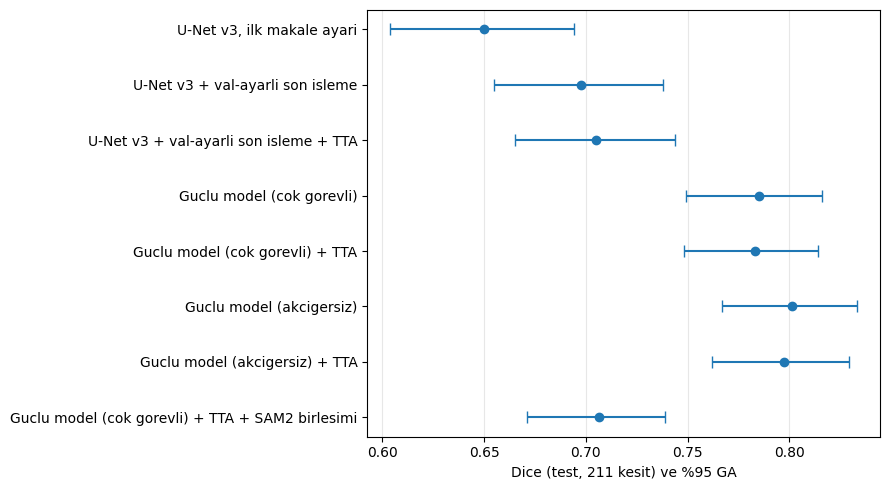

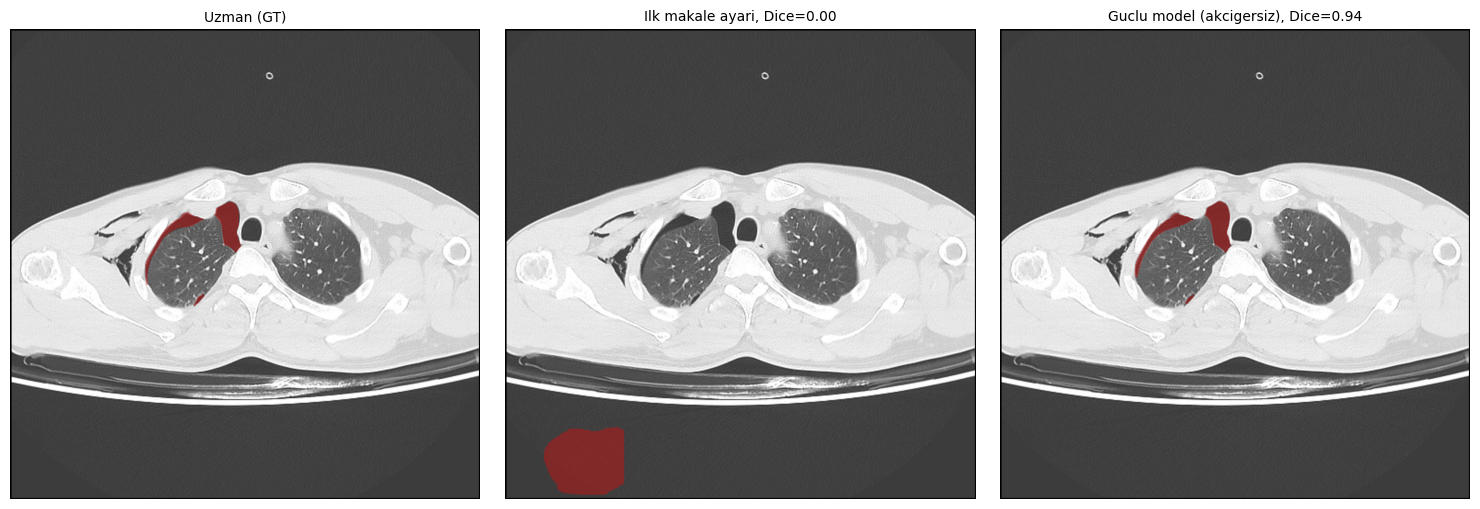

In [12]:
tum = pd.concat(TUM_SONUCLAR)
tum.to_csv(f'{OUT_DIR}/test_kesit_tum_yontemler.csv', index=False)
tablo = ozet(tum)
tablo.to_csv(f'{OUT_DIR}/TABLO_guclendirme.csv')
display(tablo.round(4))

ref = tum[tum.yontem == 'U-Net v3, ilk makale ayari'][['patient_id', 'slice', 'dice']]
ist = []
for y in tum.yontem.unique():
    if y == 'U-Net v3, ilk makale ayari':
        continue
    m = ref.merge(tum[tum.yontem == y][['patient_id', 'slice', 'dice']], on=['patient_id', 'slice'], suffixes=('_ref', '_y'))
    ist.append({'yontem': y, 'n': len(m), 'Dice ref': m.dice_ref.mean(), 'Dice': m.dice_y.mean(),
                'fark': m.dice_y.mean() - m.dice_ref.mean(), 'Wilcoxon p': stats.wilcoxon(m.dice_y, m.dice_ref).pvalue})
ist = pd.DataFrame(ist); ist.to_csv(f'{OUT_DIR}/TABLO_istatistik.csv', index=False)
print(ist.round(4))
print('\nVal setinde aday siralamasi:'); print(aday_df.round(4))

fig, ax = plt.subplots(figsize=(9, 0.5 * len(tablo.columns) + 1))
d = tablo.loc['Dice'].astype(float)
lohi = tablo.loc['Dice %95GA'].str.strip('[]').str.split(',', expand=True).astype(float)
y = np.arange(len(d))[::-1]
ax.errorbar(d.values, y, xerr=[d.values - lohi[0].values, lohi[1].values - d.values], fmt='o', capsize=4)
ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_xlabel('Dice (test, 211 kesit) ve %95 GA'); ax.grid(alpha=.3, axis='x')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_guclendirme.png', dpi=300); plt.show()

# Ornek: cok bilesenli bir test kesitinde ilk makale ayari vs en iyi yontem
en_iyi_ad = tablo.loc['Dice'].astype(float).idxmax()
a = tum[tum.yontem == 'U-Net v3, ilk makale ayari'].reset_index(drop=True)
b = tum[tum.yontem == en_iyi_ad].reset_index(drop=True)
i = int(((b.dice - a.dice) * a.cok_bilesen.astype(float)).idxmax())
im, g = VERI['test'][0][i], GT['test'][i]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax_, (t, mm) in zip(axs, [('Uzman (GT)', g),
                              (f'Ilk makale ayari, Dice={a.dice[i]:.2f}', MASKELER['U-Net v3, ilk makale ayari'][i]),
                              (f'{en_iyi_ad}, Dice={b.dice[i]:.2f}', MASKELER[en_iyi_ad][i])]):
    ax_.imshow(po.make_overlay(im, mm)); ax_.set_title(t, fontsize=10); ax_.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/SEKIL_ornek_cok_bilesen.png', dpi=200); plt.show()